# Pairs Trading Analysis — Spread & Mean Reversion

**Algothon 2026 price data** (`prices.txt`: 50+ instruments over ~750 days).

This notebook studies **statistical-arbitrage pairs**: two instruments whose
*spread* (a hedged difference) is stationary and reverts to a mean. When the
spread stretches away from its mean we short the rich leg / long the cheap leg
and profit as it snaps back.

We work through, for each pair:

| Step | What it tells us |
|---|---|
| **Hedge ratio** (OLS β) | how many units of X to trade against 1 unit of Y so the spread is market-neutral |
| **Spread** = Y − β·X | the tradeable residual we bet on |
| **Engle–Granger cointegration** *p* | is the spread genuinely stationary (not just correlated)? |
| **ADF** *p* on the spread | independent stationarity check |
| **Half-life** (Ornstein–Uhlenbeck) | how many days a shock takes to decay halfway — the natural holding period |
| **Hurst exponent** | < 0.5 ⇒ mean-reverting, ≈ 0.5 ⇒ random walk, > 0.5 ⇒ trending |
| **z-score** | how many σ the spread sits from its mean *right now* (the trade signal) |

We start with a **focus list of 13 pairs**, rank them, visualise them, then
**screen every one of the ~1,275 possible pairs** to surface many more strong
mean-reverting candidates.

## 0 · Setup

Imports, a clean/colourblind-safe plotting style, and a shared colour palette
used consistently throughout (categorical hues for series, a blue→gray→red
*diverging* map for correlations).

In [1]:
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint, adfuller
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")  # silence statsmodels' small-sample chatter
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 140)
rng = np.random.default_rng(0)

# --- Validated, colourblind-safe palette (light surface) ---------------------
CAT = ["#2a78d6", "#eb6834", "#008300", "#4a3aa7", "#eda100",
       "#1baf7a", "#e87ba4", "#e34948"]           # categorical slots
BLUE, ORANGE, GREEN, RED = "#2a78d6", "#eb6834", "#008300", "#e34948"
GRID, MUTED, INK = "#e1e0d9", "#898781", "#0b0b0b"
DIVERGING = LinearSegmentedColormap.from_list("brand_div", [BLUE, "#f0efec", RED])
SEQUENTIAL = LinearSegmentedColormap.from_list("brand_seq", ["#eaf2fc", BLUE, "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "figure.dpi": 110, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=CAT),
})
print("Setup complete.")

Setup complete.


## 1 · Load the price data

`prices.txt` is whitespace-separated, one **column per instrument** (ticker in
the header) and one **row per day**. We load it into a `prices` frame indexed by
day, plus a `log_prices` frame and a daily **log-return** frame (returns are
what we correlate; prices are what we cointegrate).

In [2]:
PRICES_FILE = "prices.txt"

prices = pd.read_csv(PRICES_FILE, sep=r"\s+")
prices.index.name = "day"
log_prices = np.log(prices)
rets = log_prices.diff().dropna()

TICKERS = list(prices.columns)
print(f"{prices.shape[0]} days x {prices.shape[1]} instruments")
print(f"Tickers: {', '.join(TICKERS)}")
prices.head()

750 days x 51 instruments
Tickers: ALGO, AENO, LSST, SRNA, ELLT, AMRP, OTCS, HETT, HUXZ, DUCT, SMAH, NPCK, MSDP, EORC, CUBO, HRET, ANSO, DIHO, RTTH, SPLZ, NWIG, MMBT, MDGI, AGVF, RRES, CTGI, ALUT, ACAC, SRTX, GARI, RCRI, ACIX, CCNS, MTNS, IHOZ, NAYO, FWWG, EELT, HRND, AETS, ULXY, BLBT, BENI, ITPA, HTRK, NGTE, ILVX, FCSG, FARS, MHRM, EAFC


,ALGO,AENO,LSST,SRNA,ELLT,AMRP,OTCS,HETT,HUXZ,DUCT,...,BLBT,BENI,ITPA,HTRK,NGTE,ILVX,FCSG,FARS,MHRM,EAFC
day,,,,,,,,,,,,,,,,,,,,,
0,100.00,116.51,113.55,134.23,64.12,25.05,14.68,59.24,83.62,19.71,...,52.23,32.37,18.82,10.86,52.65,32.58,27.46,66.43,22.41,45.08
1,98.49,112.94,114.53,133.21,62.74,23.96,14.55,58.28,79.94,19.22,...,52.73,32.25,18.41,10.77,49.71,31.66,26.47,64.66,22.10,44.28
2,97.83,112.70,112.17,132.80,61.61,23.30,14.69,57.97,81.20,19.22,...,53.23,32.23,18.22,10.69,50.53,30.84,25.28,64.19,20.87,45.30
3,98.02,112.26,116.09,133.16,63.55,23.47,14.43,57.02,81.82,19.39,...,52.67,32.20,18.22,10.28,51.64,30.95,24.60,62.80,20.95,46.32
4,99.13,113.59,119.58,137.20,63.64,23.61,14.61,58.78,83.01,19.91,...,53.59,32.33,18.25,10.50,53.57,31.49,25.66,63.94,20.72,45.56


## 2 · The focus pairs

The 13 pairs we were asked to analyse first. `Y` is the dependent leg, `X` the
hedge leg (spread = Y − β·X). We confirm every ticker exists in the data.

In [3]:
PAIRS = [("SMAH", "ILVX"), ("AENO", "NWIG"), ("EORC", "NGTE"), ("HUXZ", "ACAC"),
         ("CTGI", "EELT"), ("MHRM", "EAFC"), ("HETT", "ULXY"), ("ACIX", "ITPA"),
         ("FWWG", "BLBT"), ("RTTH", "NAYO"), ("MTNS", "ALUT"), ("NAYO", "SRTX"),
         ("ALUT", "CCNS")]

missing = sorted({t for p in PAIRS for t in p} - set(TICKERS))
assert not missing, f"Missing tickers: {missing}"
print(f"{len(PAIRS)} focus pairs, all tickers present.")

13 focus pairs, all tickers present.


## 3 · The mean-reversion toolkit

The functions below turn two price series into the metrics in the table above.

- **`hedge_ratio(y, x)`** — OLS of Y on X with an intercept; β is the slope. The
  **spread** is the regression residual, which is mean-zero by construction.
- **`half_life(spread)`** — fit the discrete Ornstein–Uhlenbeck / AR(1) model
  Δspreadₜ = λ·spreadₜ₋₁ + c. A mean-reverting spread has λ < 0, and the
  half-life of a shock is −ln 2 / λ days.
- **`hurst(series)`** — slope of log(dispersion) vs log(lag). H < 0.5 ⇒
  anti-persistent (mean-reverting), 0.5 ⇒ random walk, > 0.5 ⇒ trending.
- **`analyse_pair(y_tkr, x_tkr)`** — bundles everything into one row, using
  **Engle–Granger** `coint` (which uses the correct critical values for a
  *fitted* cointegrating vector) plus an independent **ADF** test on the spread.

In [4]:
def hedge_ratio(y, x):
    '''OLS beta and intercept of y on x (with constant).'''
    X = sm.add_constant(x.values)
    res = sm.OLS(y.values, X).fit()
    return res.params[1], res.params[0]        # beta, alpha


def make_spread(y, x):
    beta, alpha = hedge_ratio(y, x)
    spread = y - (beta * x + alpha)
    return spread, beta


def half_life(spread):
    '''OU/AR(1) half-life of mean reversion, in days.'''
    s = spread.values
    lag = s[:-1]
    delta = np.diff(s)
    lam = sm.OLS(delta, sm.add_constant(lag)).fit().params[1]
    if lam >= 0:
        return np.inf                          # not mean-reverting
    return -np.log(2) / lam


def hurst(series, max_lag=80):
    s = np.asarray(series, dtype=float)
    lags = np.arange(2, min(max_lag, len(s) // 2))
    tau = [np.std(s[l:] - s[:-l]) for l in lags]
    tau = np.maximum(tau, 1e-10)
    return np.polyfit(np.log(lags), np.log(tau), 1)[0]


def zscore(spread):
    return (spread - spread.mean()) / spread.std()


def analyse_pair(y_tkr, x_tkr):
    y, x = prices[y_tkr], prices[x_tkr]
    spread, beta = make_spread(y, x)
    z = zscore(spread)
    corr = rets[y_tkr].corr(rets[x_tkr])
    eg_p = coint(y, x)[1]                       # Engle-Granger p-value
    adf_p = adfuller(spread.values, autolag="AIC")[1]
    return {
        "pair": f"{y_tkr}~{x_tkr}", "Y": y_tkr, "X": x_tkr,
        "corr_ret": corr, "beta": beta,
        "coint_p": eg_p, "adf_p": adf_p,
        "half_life": half_life(spread), "hurst": hurst(spread),
        "spread_std": spread.std(), "z_now": z.iloc[-1], "abs_z_now": abs(z.iloc[-1]),
    }

print("Toolkit ready.")

Toolkit ready.


## 4 · Ranking the focus pairs

We run the full toolkit on each focus pair and sort by cointegration *p*-value
(lower = stronger evidence the spread is stationary). Read it as:

- **coint_p / adf_p < 0.05** → statistically cointegrated / stationary spread ✅
- **half_life** in a tradeable band (roughly 2–60 days) → reverts fast enough to
  earn but not so fast that costs dominate
- **hurst < 0.5** → confirms mean reversion
- **abs_z_now** large → the spread is stretched *today* (a live entry signal)

In [5]:
focus = pd.DataFrame(analyse_pair(y, x) for y, x in PAIRS)
focus_sorted = focus.sort_values("coint_p").reset_index(drop=True)

show_cols = ["pair", "corr_ret", "beta", "coint_p", "adf_p",
             "half_life", "hurst", "spread_std", "z_now"]
focus_sorted[show_cols].round(3)

,pair,corr_ret,beta,coint_p,adf_p,half_life,hurst,spread_std,z_now
0,SMAH~ILVX,0.295,1.398,0.000,0.000,5.689,0.166,2.516,1.148
1,AENO~NWIG,0.259,0.908,0.000,0.000,4.350,0.076,3.862,0.795
2,HUXZ~ACAC,0.303,1.111,0.000,0.000,5.699,0.111,3.289,-1.306
3,HETT~ULXY,0.160,1.080,0.000,0.000,6.672,0.157,3.746,-0.531
4,CTGI~EELT,0.226,0.939,0.000,0.000,8.416,0.158,9.944,-0.062
5,RTTH~NAYO,0.211,1.039,0.000,0.000,9.481,0.204,3.366,-0.662
6,EORC~NGTE,0.228,0.585,0.000,0.000,5.588,0.197,1.726,-0.293
7,FWWG~BLBT,0.380,0.729,0.000,0.000,9.917,0.241,1.206,0.561
8,ALUT~CCNS,0.268,0.686,0.001,0.000,12.324,0.289,1.083,-1.178
9,ACIX~ITPA,0.436,0.783,0.005,0.001,9.537,0.315,0.859,-0.298


**How many clear the bar?** The cell below counts the focus pairs that are
cointegrated at the 5% level *and* have a sensible half-life *and* Hurst < 0.5 —
i.e. genuinely tradeable, not merely correlated.

In [6]:
def tradeable(df, coint_a=0.05, hl_lo=2, hl_hi=60, hurst_hi=0.5):
    return df[(df.coint_p < coint_a) & (df.half_life.between(hl_lo, hl_hi))
              & (df.hurst < hurst_hi)]

good_focus = tradeable(focus_sorted)
print(f"{len(good_focus)} / {len(focus_sorted)} focus pairs are cointegrated, "
      f"mean-reverting, and tradeable:")
good_focus[show_cols].round(3)

12 / 13 focus pairs are cointegrated, mean-reverting, and tradeable:


,pair,corr_ret,beta,coint_p,adf_p,half_life,hurst,spread_std,z_now
0,SMAH~ILVX,0.295,1.398,0.000,0.000,5.689,0.166,2.516,1.148
1,AENO~NWIG,0.259,0.908,0.000,0.000,4.350,0.076,3.862,0.795
2,HUXZ~ACAC,0.303,1.111,0.000,0.000,5.699,0.111,3.289,-1.306
3,HETT~ULXY,0.160,1.080,0.000,0.000,6.672,0.157,3.746,-0.531
4,CTGI~EELT,0.226,0.939,0.000,0.000,8.416,0.158,9.944,-0.062
5,RTTH~NAYO,0.211,1.039,0.000,0.000,9.481,0.204,3.366,-0.662
6,EORC~NGTE,0.228,0.585,0.000,0.000,5.588,0.197,1.726,-0.293
7,FWWG~BLBT,0.380,0.729,0.000,0.000,9.917,0.241,1.206,0.561
8,ALUT~CCNS,0.268,0.686,0.001,0.000,12.324,0.289,1.083,-1.178
9,ACIX~ITPA,0.436,0.783,0.005,0.001,9.537,0.315,0.859,-0.298


## 5 · Visualising every focus pair

For each pair we plot the **z-score of the spread** with ±1σ / ±2σ bands. A good
mean-reverting pair oscillates through zero and rarely stays pinned outside ±2σ.
Pairs are ordered by cointegration strength (best first); the subtitle shows the
half-life and current z.

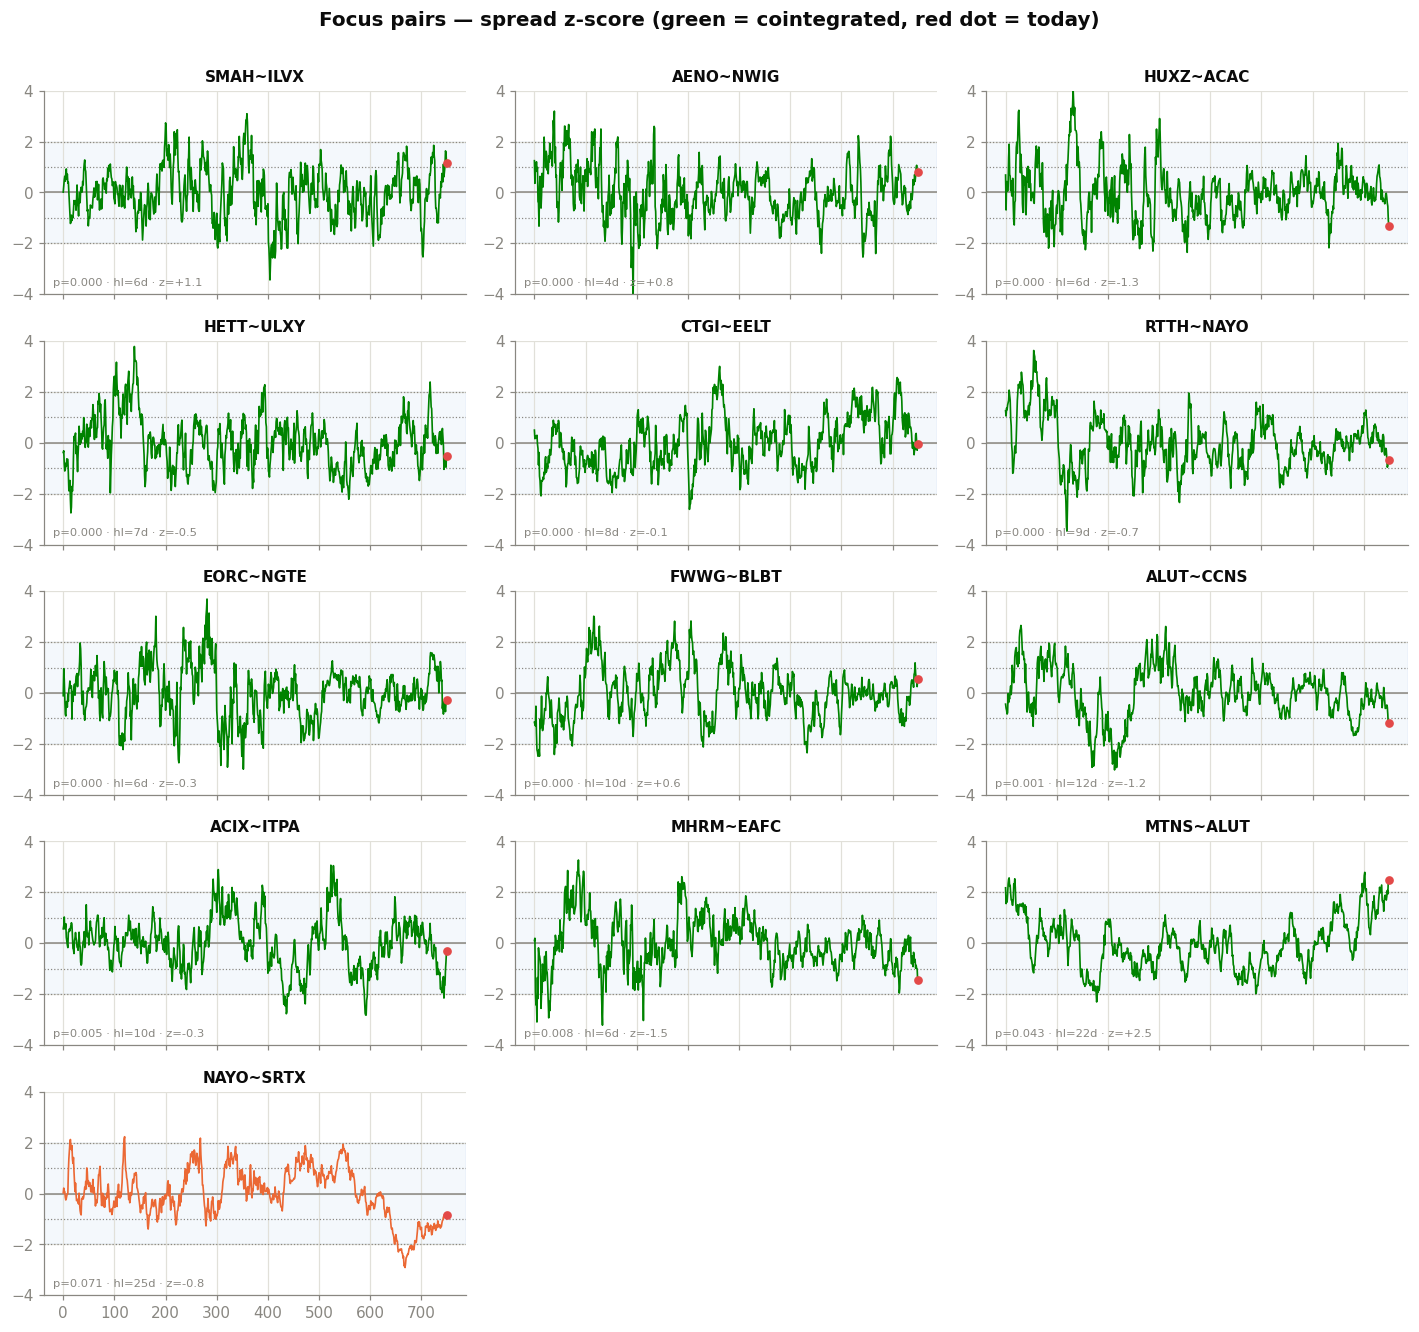

In [7]:
def zscore_panel(ax, row):
    y, x = prices[row.Y], prices[row.X]
    spread, _ = make_spread(y, x)
    z = zscore(spread)
    ax.axhspan(-2, 2, color=BLUE, alpha=0.05)
    ax.axhline(0, color=MUTED, lw=1)
    for lvl in (1, 2):
        ax.axhline(lvl, color=MUTED, ls=":", lw=0.8)
        ax.axhline(-lvl, color=MUTED, ls=":", lw=0.8)
    col = GREEN if row.coint_p < 0.05 else ORANGE
    ax.plot(z.index, z.values, color=col, lw=1.1)
    ax.scatter(z.index[-1], z.iloc[-1], color=RED, s=22, zorder=5)  # today
    ax.set_title(row.pair, fontsize=10)
    ax.text(0.02, 0.04,
            f"p={row.coint_p:.3f} · hl={row.half_life:.0f}d · z={row.z_now:+.1f}",
            transform=ax.transAxes, fontsize=7.5, color=MUTED)
    ax.set_ylim(-4, 4)


n = len(focus_sorted)
ncol = 3
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 2.4 * nrow), sharex=True)
for ax, (_, row) in zip(axes.flat, focus_sorted.iterrows()):
    zscore_panel(ax, row)
for ax in axes.flat[n:]:
    ax.axis("off")
fig.suptitle("Focus pairs — spread z-score (green = cointegrated, red dot = today)",
             fontsize=13, fontweight="bold", y=1.005)
fig.tight_layout()
plt.show()

## 6 · Deep dive on the strongest focus pair

Three stacked panels for the top-ranked pair:

1. **Normalised prices** (both legs rebased to 100) — you should see them track.
2. **Spread with its mean and ±2σ bands** — the thing we actually trade.
3. **z-score with shaded trade zones** — long the spread below −2, short above
   +2, exit near 0.

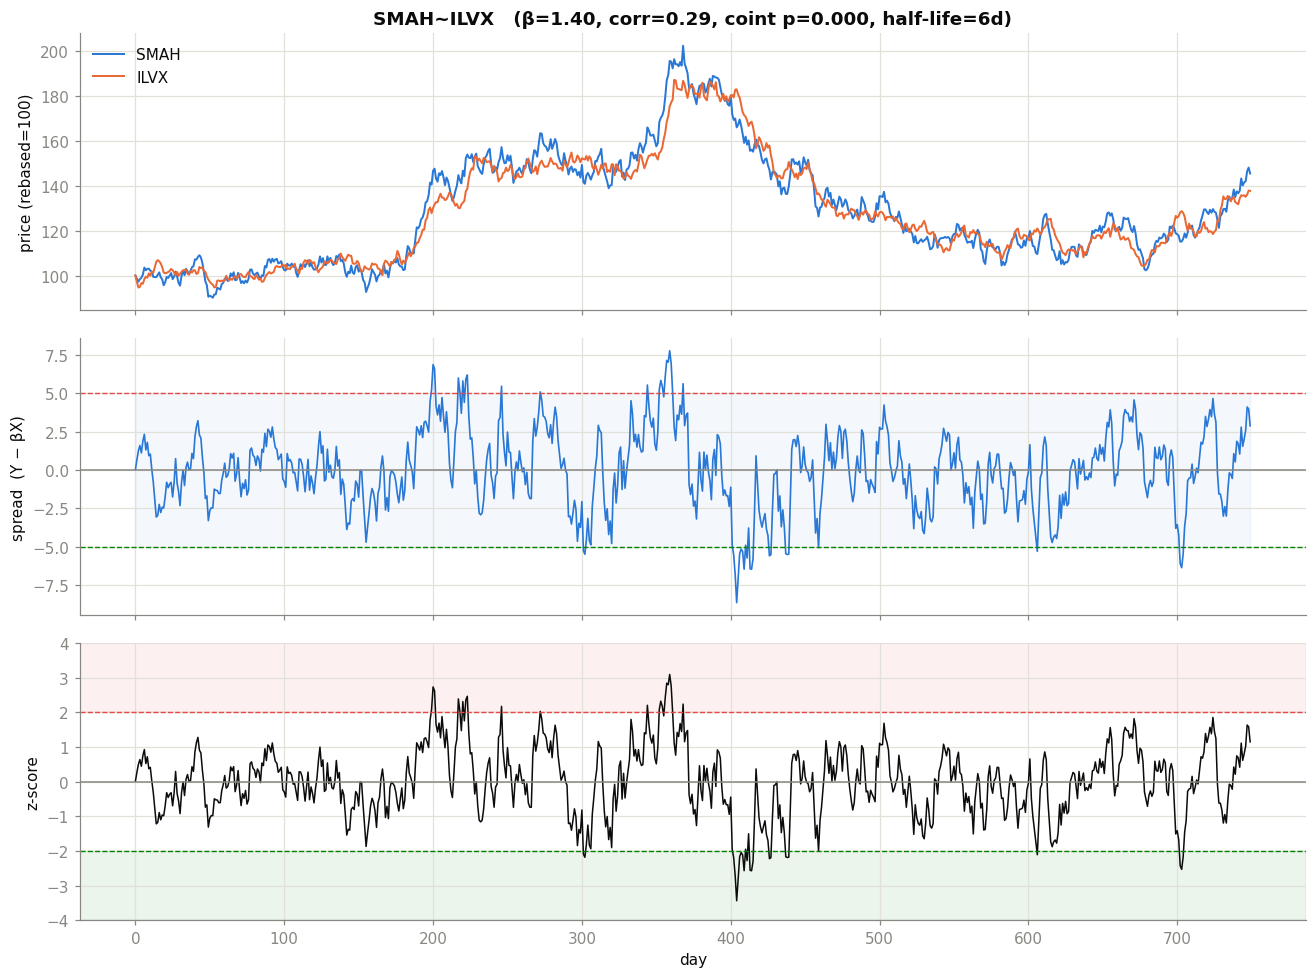

In [8]:
best = focus_sorted.iloc[0]
y, x = prices[best.Y], prices[best.X]
spread, beta = make_spread(y, x)
z = zscore(spread)
mu, sd = spread.mean(), spread.std()

fig, (a0, a1, a2) = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

a0.plot(prices.index, 100 * y / y.iloc[0], color=BLUE, lw=1.3, label=best.Y)
a0.plot(prices.index, 100 * x / x.iloc[0], color=ORANGE, lw=1.3, label=best.X)
a0.set_title(f"{best.pair}   (β={beta:.2f}, corr={best.corr_ret:.2f}, "
             f"coint p={best.coint_p:.3f}, half-life={best.half_life:.0f}d)")
a0.set_ylabel("price (rebased=100)")
a0.legend(frameon=False, loc="upper left")

a1.plot(spread.index, spread.values, color=BLUE, lw=1.1)
a1.axhline(mu, color=MUTED, lw=1)
a1.axhline(mu + 2 * sd, color=RED, ls="--", lw=0.9)
a1.axhline(mu - 2 * sd, color=GREEN, ls="--", lw=0.9)
a1.fill_between(spread.index, mu - 2 * sd, mu + 2 * sd, color=BLUE, alpha=0.05)
a1.set_ylabel("spread  (Y − βX)")

a2.plot(z.index, z.values, color=INK, lw=1.0)
a2.axhline(0, color=MUTED, lw=1)
a2.axhspan(2, 4, color=RED, alpha=0.08)     # short zone
a2.axhspan(-4, -2, color=GREEN, alpha=0.08) # long zone
a2.axhline(2, color=RED, ls="--", lw=0.9)
a2.axhline(-2, color=GREEN, ls="--", lw=0.9)
a2.set_ylabel("z-score"); a2.set_xlabel("day"); a2.set_ylim(-4, 4)
fig.tight_layout()
plt.show()

## 7 · Correlation structure of the focus universe

Return correlation across the tickers involved in the focus pairs. This is a
*diverging* quantity (−1 … +1) so we use a blue↔red map with a neutral-gray
midpoint. Strongly positive blocks are candidate pairs; the focus pairs should
light up.

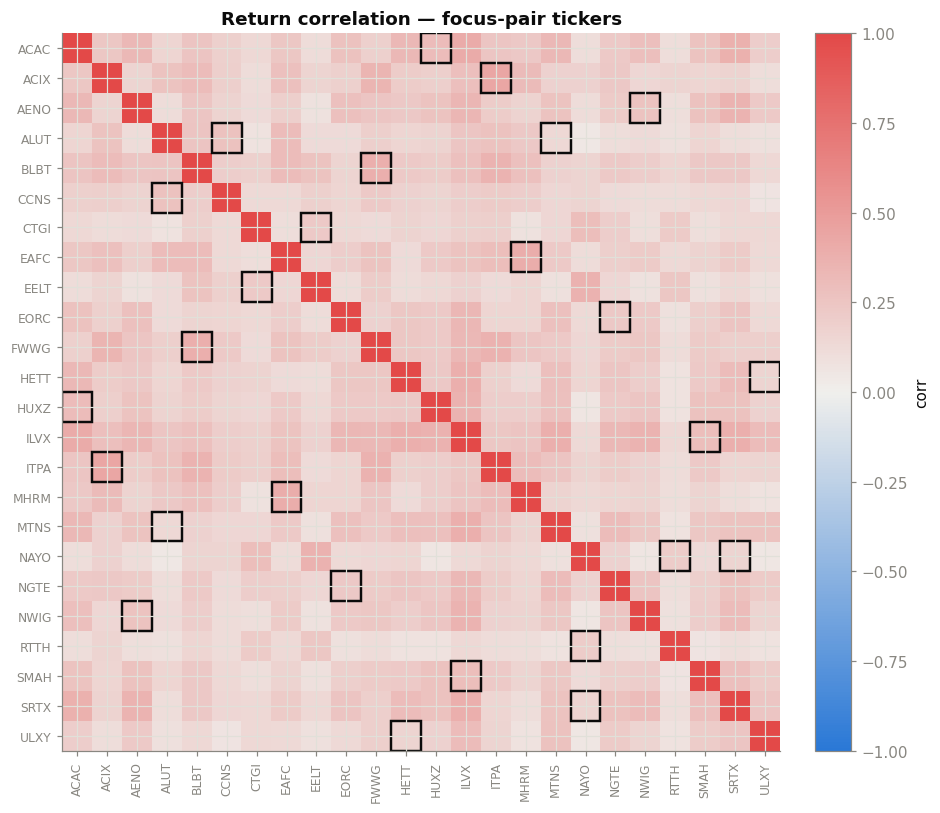

In [9]:
focus_tkrs = sorted({t for p in PAIRS for t in p})
cm = rets[focus_tkrs].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(focus_tkrs))); ax.set_xticklabels(focus_tkrs, rotation=90, fontsize=8)
ax.set_yticks(range(len(focus_tkrs))); ax.set_yticklabels(focus_tkrs, fontsize=8)
ax.set_title("Return correlation — focus-pair tickers")
# mark the focus pairs
idx = {t: i for i, t in enumerate(focus_tkrs)}
for yv, xv in PAIRS:
    ax.add_patch(plt.Rectangle((idx[xv] - .5, idx[yv] - .5), 1, 1,
                 fill=False, edgecolor=INK, lw=1.6))
    ax.add_patch(plt.Rectangle((idx[yv] - .5, idx[xv] - .5), 1, 1,
                 fill=False, edgecolor=INK, lw=1.6))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="corr")
fig.tight_layout()
plt.show()

## 8 · Screening *all* pairs — finding many more

Now the discovery step. We run the same cointegration + half-life + Hurst
pipeline over **every** one of the C(n, 2) ≈ 1,275 unordered pairs and keep the
statistics. (Direction is fixed by ticker order for speed; the sign of β sorts
itself out per pair.) This is the heavy cell — expect a short wait.

In [10]:
def screen_pair(a, b):
    y, x = prices[a], prices[b]
    spread, beta = make_spread(y, x)
    try:
        eg_p = coint(y, x)[1]
    except Exception:
        eg_p = np.nan
    return {
        "pair": f"{a}~{b}", "Y": a, "X": b,
        "corr_ret": rets[a].corr(rets[b]), "beta": beta,
        "coint_p": eg_p, "half_life": half_life(spread),
        "hurst": hurst(spread), "spread_std": spread.std(),
        "z_now": zscore(spread).iloc[-1],
    }

all_pairs = list(combinations(TICKERS, 2))
print(f"Screening {len(all_pairs)} pairs ...")
screen = pd.DataFrame(screen_pair(a, b) for a, b in all_pairs)
screen["abs_z_now"] = screen.z_now.abs()
focus_sets = {frozenset(p) for p in PAIRS}       # order-independent membership
screen["is_focus"] = [frozenset((a, b)) in focus_sets for a, b in zip(screen.Y, screen.X)]
print("done.")
screen.describe().round(3)

Screening 1275 pairs ...
done.


,corr_ret,beta,coint_p,half_life,hurst,spread_std,z_now,abs_z_now
count,1275.000,1275.000,1275.000,1275.000,1275.000,1275.000,1275.000,1275.000
mean,0.207,0.620,0.472,102.943,0.438,11.421,-0.054,1.023
std,0.088,2.346,0.280,358.470,0.076,11.224,1.215,0.657
min,-0.002,-19.010,0.000,4.350,0.076,0.799,-2.843,0.002
25%,0.144,-0.073,0.222,39.851,0.395,4.324,-1.057,0.501
50%,0.193,0.265,0.469,60.221,0.442,7.536,-0.192,0.969
75%,0.256,0.944,0.704,97.616,0.492,14.980,0.834,1.446
max,0.612,22.796,0.985,8988.954,0.649,64.800,3.606,3.606


### 8a · The best candidates overall

Apply the same tradeability filter (cointegrated at 5%, half-life 2–60 days,
Hurst < 0.5) and rank by cointegration strength. We flag which were already in
the focus list so the rest are genuinely **new** ideas.

In [11]:
ranked = tradeable(screen).sort_values("coint_p").reset_index(drop=True)
print(f"{len(ranked)} of {len(screen)} pairs pass the tradeability filter "
      f"({screen.is_focus.sum()} focus pairs screened).")

cols = ["pair", "corr_ret", "beta", "coint_p", "half_life", "hurst",
        "z_now", "is_focus"]
ranked.head(30)[cols].round(3)

79 of 1275 pairs pass the tradeability filter (13 focus pairs screened).


,pair,corr_ret,beta,coint_p,half_life,hurst,z_now,is_focus
0,SMAH~ILVX,0.295,1.398,0.000,5.689,0.166,1.148,True
1,AENO~NWIG,0.259,0.908,0.000,4.350,0.076,0.795,True
2,HUXZ~ACAC,0.303,1.111,0.000,5.699,0.111,-1.306,True
3,HETT~ULXY,0.160,1.080,0.000,6.672,0.157,-0.531,True
4,CTGI~EELT,0.226,0.939,0.000,8.416,0.158,-0.062,True
5,RTTH~NAYO,0.211,1.039,0.000,9.481,0.204,-0.662,True
6,EORC~NGTE,0.228,0.585,0.000,5.588,0.197,-0.293,True
7,FWWG~BLBT,0.380,0.729,0.000,9.917,0.241,0.561,True
8,MTNS~BENI,0.362,0.614,0.000,11.188,0.219,1.035,False
9,SRTX~MHRM,0.108,12.866,0.001,12.218,0.258,-1.519,False


### 8b · Many more — top brand-new pairs not in the focus list

These are the strongest mean-reverting pairs the screen discovered beyond the
original 13. Also stretched *today* (|z| high) ⇒ actionable right now.

In [12]:
new_ideas = ranked[~ranked.is_focus].reset_index(drop=True)
print(f"{len(new_ideas)} new tradeable pairs discovered.")
print("\n-- Top 25 new pairs by cointegration strength --")
display(new_ideas.head(25)[["pair", "corr_ret", "beta", "coint_p",
                            "half_life", "hurst", "z_now"]].round(3))

print("\n-- Of those, most stretched TODAY (|z_now| >= 2) --")
live = new_ideas[new_ideas.abs_z_now >= 2].sort_values("abs_z_now", ascending=False)
display(live.head(15)[["pair", "coint_p", "half_life", "hurst", "z_now"]].round(3))

68 new tradeable pairs discovered.

-- Top 25 new pairs by cointegration strength --


,pair,corr_ret,beta,coint_p,half_life,hurst,z_now
0,MTNS~BENI,0.362,0.614,0.000,11.188,0.219,1.035
1,SRTX~MHRM,0.108,12.866,0.001,12.218,0.258,-1.519
2,RTTH~SPLZ,0.159,0.264,0.002,15.228,0.309,-0.922
3,MTNS~FCSG,0.168,-0.108,0.002,14.626,0.237,1.830
4,NAYO~BLBT,0.157,0.782,0.003,15.392,0.288,-0.046
5,SPLZ~NAYO,0.112,3.432,0.003,15.200,0.322,-0.035
6,NAYO~FWWG,0.143,1.047,0.003,15.166,0.291,-0.309
7,SRTX~EAFC,0.216,6.260,0.004,17.107,0.305,-2.105
8,EELT~FARS,0.130,-0.884,0.004,14.405,0.257,-1.944
9,RTTH~BLBT,0.154,0.906,0.004,18.217,0.313,-0.361



-- Of those, most stretched TODAY (|z_now| >= 2) --


,pair,coint_p,half_life,hurst,z_now
19,ELLT~HTRK,0.009,17.532,0.269,-2.843
53,MTNS~ITPA,0.034,20.796,0.262,2.502
66,MTNS~IHOZ,0.048,22.734,0.268,2.500
48,MTNS~ILVX,0.031,20.594,0.269,2.441
58,MTNS~MHRM,0.045,22.206,0.259,2.415
59,MTNS~EAFC,0.045,22.183,0.260,2.385
24,MTNS~HTRK,0.012,17.817,0.255,2.315
52,MTNS~BLBT,0.033,21.613,0.261,2.303
43,MTNS~AETS,0.027,21.011,0.262,2.299
49,MTNS~FWWG,0.031,21.435,0.261,2.282


## 9 · Landscape of the whole screen

Every screened pair plotted as **half-life (x, log scale) vs cointegration
*p*-value (y)**. The shaded box is the tradeable zone (p < 0.05, half-life
2–60d). Focus pairs are highlighted; the best new discoveries are labelled.

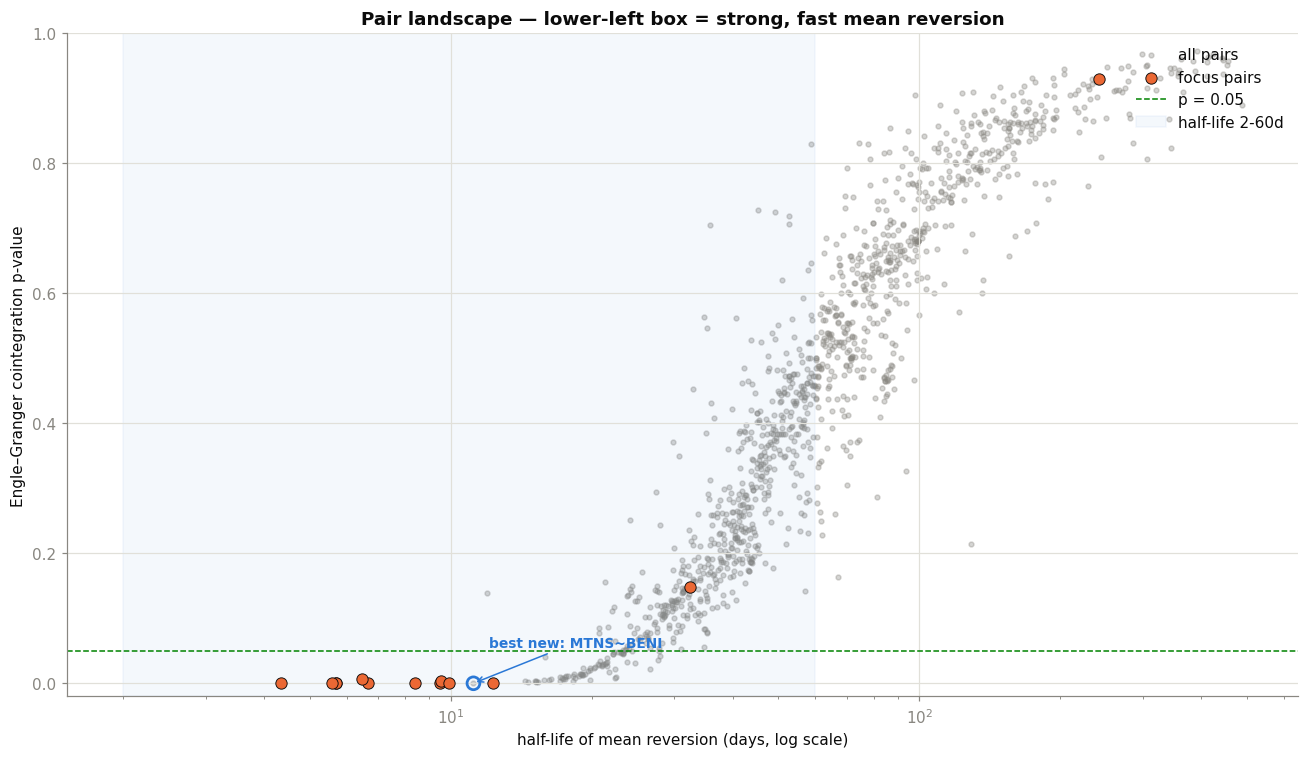

In [13]:
plot_df = screen[np.isfinite(screen.half_life) & screen.half_life.between(1, 500)]

fig, ax = plt.subplots(figsize=(12, 7))
bg = plot_df[~plot_df.is_focus]
ax.scatter(bg.half_life, bg.coint_p, s=10, color=MUTED, alpha=0.35,
           label="all pairs")
fc = plot_df[plot_df.is_focus]
ax.scatter(fc.half_life, fc.coint_p, s=55, color=ORANGE, edgecolor=INK,
           lw=0.6, label="focus pairs", zorder=4)

# tradeable zone (p < 0.05 AND half-life 2-60d)
ax.axhline(0.05, color=GREEN, ls="--", lw=1, label="p = 0.05")
ax.axvspan(2, 60, color=BLUE, alpha=0.05, label="half-life 2-60d")
# highlight the single strongest new discovery (rest are named in the table above)
nd = new_ideas.iloc[0]
if 1 <= nd.half_life <= 500:
    ax.scatter(nd.half_life, nd.coint_p, s=70, facecolor="none",
               edgecolor=BLUE, lw=1.8, zorder=6)
    ax.annotate(f"best new: {nd.pair}", (nd.half_life, nd.coint_p),
                fontsize=9, color=BLUE, fontweight="bold",
                xytext=(10, 24), textcoords="offset points",
                arrowprops=dict(arrowstyle="->", color=BLUE, lw=1))

ax.set_xscale("log")
ax.set_xlabel("half-life of mean reversion (days, log scale)")
ax.set_ylabel("Engle–Granger cointegration p-value")
ax.set_ylim(-0.02, 1.0)
ax.set_title("Pair landscape — lower-left box = strong, fast mean reversion")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

### Grid of the top discovered pairs

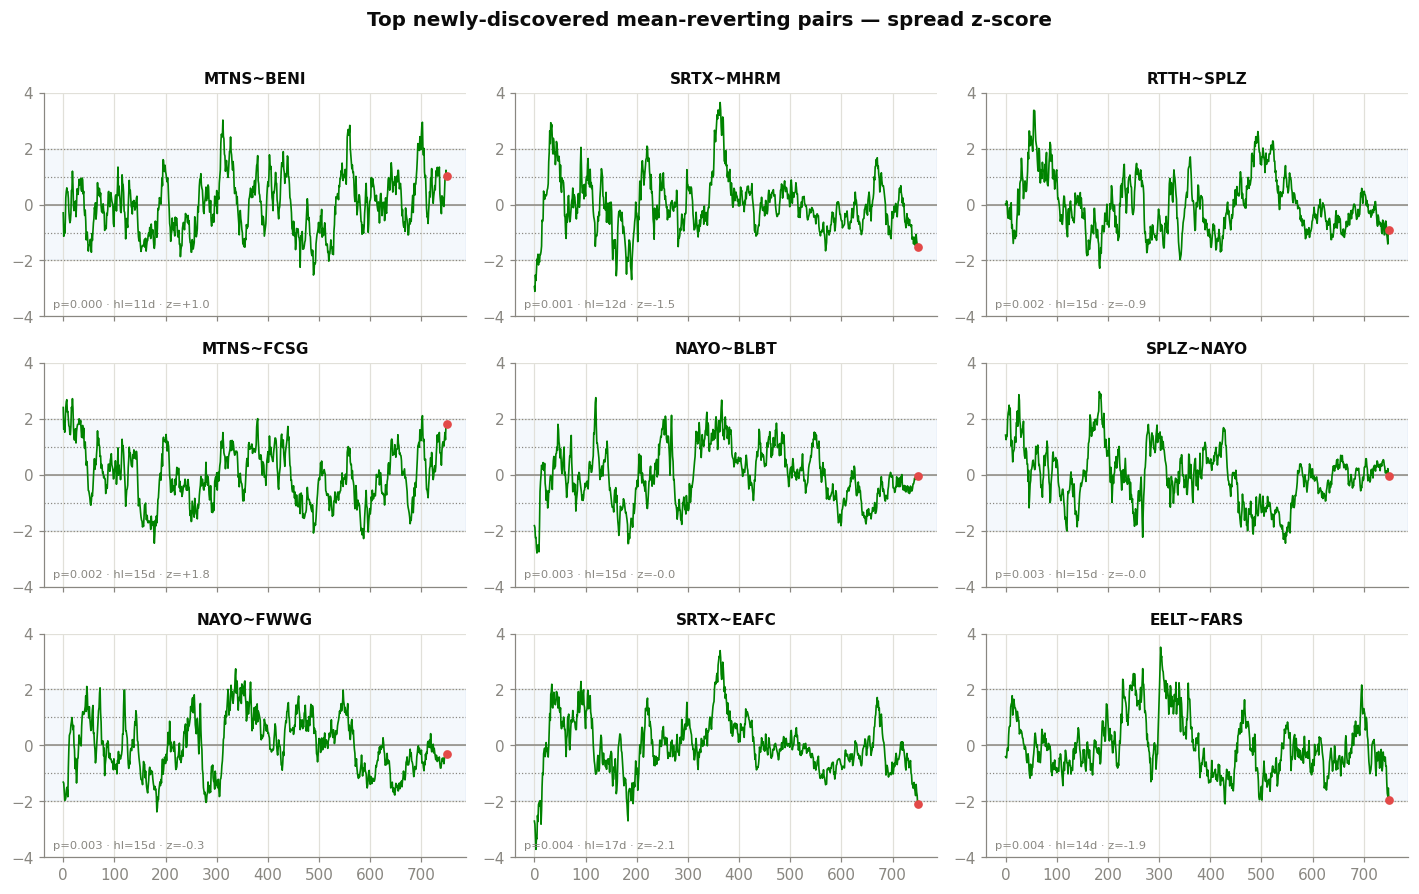

In [14]:
top_new = new_ideas.head(9)
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
for ax, (_, row) in zip(axes.flat, top_new.iterrows()):
    zscore_panel(ax, row)
for ax in axes.flat[len(top_new):]:
    ax.axis("off")
fig.suptitle("Top newly-discovered mean-reverting pairs — spread z-score",
             fontsize=13, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

## 10 · A toy z-score backtest

To sanity-check that a stretched spread actually *pays*, we run the textbook
rule on a chosen pair over the full history:

- enter **short spread** (short Y, long β·X) when z ≥ +2, **long spread** when z ≤ −2
- **exit** when z crosses back through 0
- position sign held between signals; PnL ≈ position · Δspread (β-neutral units)

This ignores commission and position limits (see `eval.py` for the real scoring)
— it's a directional check on the *edge*, not a submission.

SMAH~ILVX:  ann.Sharpe=2.55  total spread-PnL=73.7  approx trades=24


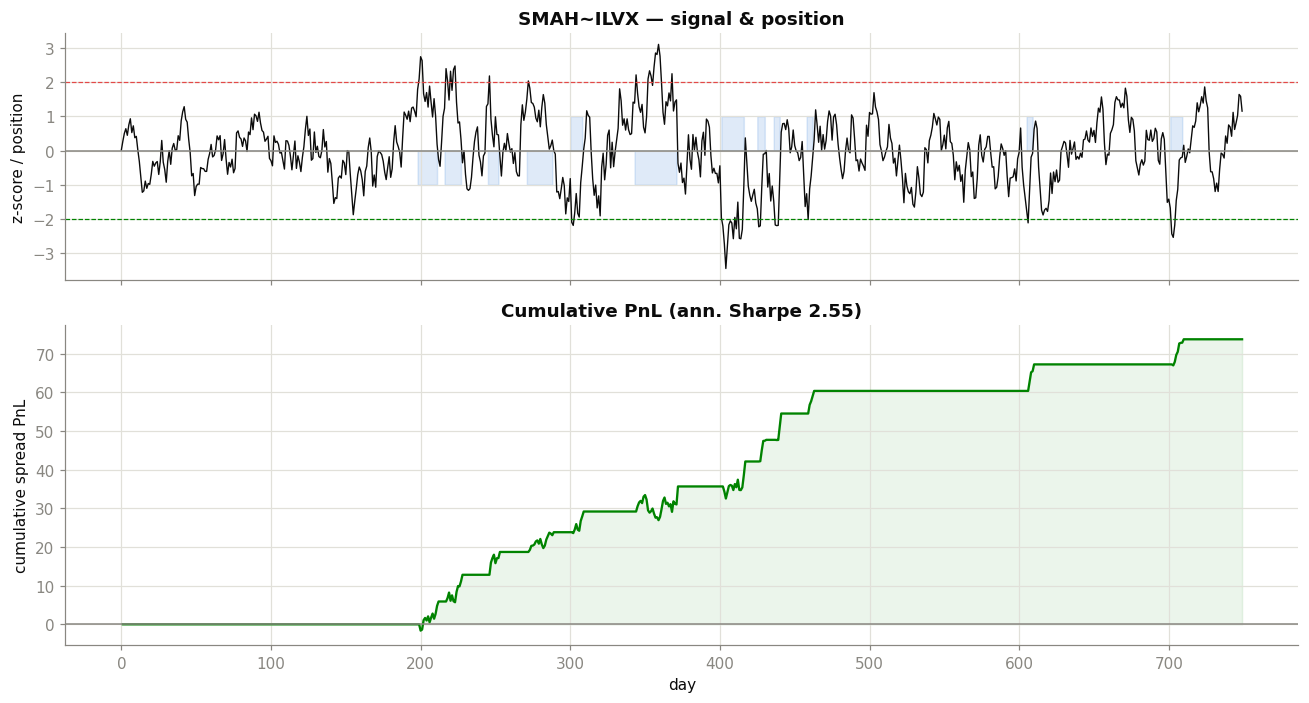

In [15]:
def backtest_zscore(y_tkr, x_tkr, entry=2.0, exit=0.0, lookback=None):
    y, x = prices[y_tkr], prices[x_tkr]
    spread, beta = make_spread(y, x)
    if lookback:
        z = (spread - spread.rolling(lookback).mean()) / spread.rolling(lookback).std()
    else:
        z = zscore(spread)
    pos = np.zeros(len(z))
    cur = 0
    for i in range(1, len(z)):
        zi = z.iloc[i]
        if cur == 0:
            if zi >= entry: cur = -1            # spread rich -> short it
            elif zi <= -entry: cur = 1          # spread cheap -> long it
        elif cur == 1 and zi >= -exit: cur = 0
        elif cur == -1 and zi <= exit: cur = 0
        pos[i] = cur
    dspread = spread.diff().fillna(0).values
    pnl = pos[:-1] * dspread[1:]                # yesterday's position earns today's move
    pnl = pd.Series(pnl, index=spread.index[1:])
    sharpe = np.sqrt(250) * pnl.mean() / pnl.std() if pnl.std() > 0 else 0.0
    return spread, z, pd.Series(pos, index=spread.index), pnl, sharpe


bt_pair = best.Y, best.X                        # backtest the strongest focus pair
spread, z, pos, pnl, sharpe = backtest_zscore(*bt_pair)
cum = pnl.cumsum()
trades = int((pos.diff().abs() > 0).sum())
print(f"{bt_pair[0]}~{bt_pair[1]}:  ann.Sharpe={sharpe:.2f}  "
      f"total spread-PnL={cum.iloc[-1]:.1f}  approx trades={trades}")

fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1.3]})
a0.plot(z.index, z.values, color=INK, lw=0.9)
a0.axhline(2, color=RED, ls="--", lw=0.8); a0.axhline(-2, color=GREEN, ls="--", lw=0.8)
a0.axhline(0, color=MUTED, lw=1)
a0.fill_between(pos.index, 0, pos.values, step="pre", color=BLUE, alpha=0.15)
a0.set_ylabel("z-score / position"); a0.set_title(f"{bt_pair[0]}~{bt_pair[1]} — signal & position")

a1.plot(cum.index, cum.values, color=GREEN, lw=1.5)
a1.axhline(0, color=MUTED, lw=1)
a1.fill_between(cum.index, 0, cum.values, color=GREEN, alpha=0.08)
a1.set_ylabel("cumulative spread PnL"); a1.set_xlabel("day")
a1.set_title(f"Cumulative PnL (ann. Sharpe {sharpe:.2f})")
fig.tight_layout()
plt.show()

### Backtest the whole tradeable shortlist

Run the same rule across every pair that passed the filter and rank by
back-tested Sharpe — a quick way to see which cointegration signals convert into
the most robust in-sample edge. (In-sample, no costs — treat as a screen, not a
promise.)

In [ ]:
bt_rows = []
for _, r in ranked.iterrows():
    _, _, _, pnl_i, sh_i = backtest_zscore(r.Y, r.X)
    bt_rows.append({"pair": r.pair, "coint_p": r.coint_p, "half_life": r.half_life,
                    "hurst": r.hurst, "bt_sharpe": sh_i,
                    "bt_total_pnl": pnl_i.sum(), "is_focus": r.is_focus})

bt = pd.DataFrame(bt_rows).sort_values("bt_sharpe", ascending=False).reset_index(drop=True)
print(f"Backtested {len(bt)} tradeable pairs. Top 20 by in-sample Sharpe:")
bt.head(20).round(3)

Backtested 79 tradeable pairs. Top 20 by in-sample Sharpe:


,pair,coint_p,half_life,hurst,bt_sharpe,bt_total_pnl,is_focus
0,HUXZ~ACAC,0.000,5.699,0.111,2.680,101.653,True
1,SMAH~ILVX,0.000,5.689,0.166,2.549,73.742,True
2,AENO~NWIG,0.000,4.350,0.076,2.455,142.501,True
3,MTNS~FCSG,0.002,14.626,0.237,2.450,17.814,False
4,RCRI~CCNS,0.023,22.419,0.370,2.302,85.452,False
5,SRTX~CCNS,0.008,22.383,0.326,2.285,341.270,False
6,MTNS~HTRK,0.012,17.817,0.255,2.132,16.134,False
7,IHOZ~EAFC,0.024,19.797,0.323,2.092,108.390,False
8,RTTH~GARI,0.046,23.131,0.358,2.054,52.792,False
9,MTNS~ITPA,0.034,20.796,0.262,1.981,15.423,False


: 

## 11 · Takeaways

- **Spread construction.** Every pair is reduced to a β-hedged residual
  `spread = Y − βX`; the whole analysis is about whether that residual is
  stationary and how fast it reverts.
- **Not all correlation is cointegration.** The `coint_p` / `adf_p` columns
  separate pairs that merely move together from those whose spread actually
  reverts — only the latter are tradeable.
- **Half-life = holding period.** It sets both the natural exit horizon and how
  much turnover (and therefore commission, per `eval.py`) a pair will incur.
- **Screening pays.** Beyond the 13 focus pairs, the all-pairs sweep surfaces
  many more cointegrated, fast-reverting candidates — ranked in §8b and
  back-tested in §10.

**Turning this into `getMyPosition`:** pick the pairs that survive *every* screen
(low coint_p, half-life in band, Hurst < 0.5, positive in-sample Sharpe), size
each leg β-neutral, and set target positions from the live z-score (short the
spread when z ≫ 0, long when z ≪ 0, flat near 0), then clip to the dollar
position limits the evaluator enforces.

> ⚠️ All tests here are **in-sample** over the full history. Before trusting a
> pair, re-fit β and the spread mean on a training window and confirm the
> reversion holds out-of-sample — cointegration can and does break.